# 06 · Modelado predictivo: ¿qué clientes volverán a comprar en los próximos 90 días?

**Proyecto final · Análisis de Datos + Inteligencia de Negocios + Aprendizaje Computacional · ITM 2026-2**
Dataset: Online Retail II (UCI, DOI 10.24432/C5CG6D) · Grupo 3

En los notebooks 01 a 05 se limpió el dato (ETL), se exploró, se validaron hipótesis y se construyó el dashboard. Ahí apareció el problema de negocio central: **la retención es el cuello de botella** (solo 46,7 % de los clientes recompra en 90 días y el 20 % de los clientes genera ~77 % del ingreso). Este notebook cierra el ciclo con un **modelo supervisado** que anticipa qué clientes volverán a comprar, para decidir **a quién dirigir las campañas de retención**.

**Qué contiene**

1. Planteamiento del problema predictivo y de la métrica.
2. Construcción de la base de modelado **sin fuga de información** (cortes temporales).
3. División temporal y validación cruzada temporal.
4. Línea base, tres algoritmos y ajuste de hiperparámetros.
5. Evaluación final en un periodo posterior que el modelo nunca vio.
6. Interpretación (importancia, dependencia parcial, estabilidad, equidad).
7. Valor de negocio (ganancia por deciles) y exportación de resultados al dashboard.
8. Limitaciones, ética y conclusiones.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, randint

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.calibration import calibration_curve

SEMILLA = 42
np.random.seed(SEMILLA)

# Rutas del proyecto (los notebooks viven en /notebooks)
RAIZ = Path('..').resolve()
PROC = RAIZ / 'data' / 'processed'
SALIDA = PROC / 'modelo_predictivo'
FIG = RAIZ / 'docs' / 'figuras'
SALIDA.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# Estilo comun a todos los graficos del proyecto
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, NARANJA, GRIS, VERDE, ROJO = '#1F4E79', '#E8833A', '#8C8C8C', '#3B8E5A', '#C0392B'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

R = {}   # cifras que luego usa la interpretacion


def coma(x, d=1):
    """Formato con coma decimal para el texto en espanol."""
    return f'{x:,.{d}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

## 1. Planteamiento del problema predictivo

| Elemento | Decisión |
|---|---|
| **Problema de negocio** | La mayor parte del ingreso depende de pocos clientes y la recompra es baja. No se puede llamar o escribir a todos: hay que **priorizar**. |
| **Pregunta predictiva** | Dado lo que sabemos de un cliente hasta hoy, ¿**comprará al menos una vez en los próximos 90 días**? |
| **Tipo de problema** | Clasificación supervisada binaria. |
| **Unidad de análisis** | Un **cliente en una fecha de corte** (por eso un mismo cliente aparece varias veces, una por cada corte). |
| **Variable objetivo** | `y = 1` si hay al menos un pedido de venta entre el corte (incluido) y 90 días después; `0` si no. |
| **Clientes incluidos** | Solo clientes **identificados** con al menos un pedido antes del corte. Los clientes sin identificar (22 % de las líneas) no se pueden contactar ni seguir en el tiempo. |
| **Uso del modelo** | Ordenar a los clientes por probabilidad de recompra para decidir **a quién retener o reactivar** y con qué prioridad. |

### Métrica principal

- **PR-AUC** (área bajo la curva precisión-recall): mide qué tan bien el modelo pone a los compradores arriba de la lista. Se prefiere sobre el *accuracy* porque la tasa base cambia con la temporada (entre ~32 % y ~62 % según el corte) y el accuracy depende de ese nivel.
- **ROC-AUC**: probabilidad de que un comprador reciba mayor puntaje que un no comprador. Complementa a la PR-AUC.
- **Brier y curva de calibración**: porque se usará la *probabilidad*, no solo el sí/no.
- **Captura en el 30 % superior** (*gain*): qué proporción de los compradores y del ingreso futuro queda dentro del 30 % de clientes con mayor puntaje. Es la métrica que entiende el negocio.
- Como **línea base** se usa una regla sin aprendizaje: *"cuanto más reciente la última compra, más probable la recompra"*. El modelo solo vale la pena si la supera con claridad.

## 2. Construcción de la base de modelado sin fuga de información

**Regla de oro:** para cada fecha de corte `t`, las variables se calculan **solo con información anterior a `t`** y el objetivo se mide **después de `t`**. Así el modelo nunca ve el futuro que intenta predecir.

Se toma **un corte por mes** (1.º de cada mes). Cada corte aporta una fila por cada cliente identificado que ya había comprado. Esto equivale a "tomar una foto" mensual de la cartera, como se haría al usar el modelo en la vida real.

In [2]:
fact = pd.read_parquet(PROC / 'modelo_bi' / 'fact_lineas.parquet')
dim_cliente = pd.read_parquet(PROC / 'modelo_bi' / 'dim_cliente.parquet')[['cliente_key', 'pais_grupo_cliente']]

fact = fact[fact['cliente_key'] != -1]                       # solo clientes identificados
ventas = fact[fact['tipo'] == 'Venta']
devol = fact[fact['tipo'] == 'Devolucion']

# Un pedido = una factura de venta (se agregan sus lineas)
pedidos = (ventas.groupby(['cliente_key', 'factura'], as_index=False)
           .agg(fecha=('fecha', 'min'), importe=('importe', 'sum'),
                lineas=('codigo', 'size'), unidades=('cantidad', 'sum')))
print(f'{len(pedidos):,} pedidos de {pedidos["cliente_key"].nunique():,} clientes identificados')
print(f'Periodo: {pedidos["fecha"].min():%Y-%m-%d} a {pedidos["fecha"].max():%Y-%m-%d}')

36,592 pedidos de 5,852 clientes identificados
Periodo: 2009-12-01 a 2011-12-09


In [3]:
HORIZONTE = 90                                              # dias hacia adelante que se quieren predecir
CORTES = pd.date_range('2010-03-01', '2011-09-01', freq='MS')  # el ultimo corte con 90 dias completos de futuro


def variables_al_corte(corte, con_objetivo=True):
    """Foto de cada cliente en la fecha `corte`: variables con datos < corte y objetivo con datos >= corte."""
    hist = pedidos[pedidos['fecha'] < corte]
    g = hist.groupby('cliente_key')
    X = g.agg(frecuencia=('factura', 'nunique'), monetario=('importe', 'sum'),
              primera=('fecha', 'min'), ultima=('fecha', 'max'),
              lineas_medias=('lineas', 'mean'), unidades_medias=('unidades', 'mean'),
              ticket_medio=('importe', 'mean'))
    X['recencia'] = (corte - X['ultima']).dt.days
    X['antiguedad'] = (corte - X['primera']).dt.days
    X['intervalo_medio'] = np.where(X['frecuencia'] > 1,
                                    (X['ultima'] - X['primera']).dt.days / (X['frecuencia'] - 1).clip(lower=1), np.nan)
    for dias, nombre in [(90, '90d'), (180, '180d')]:
        v = hist[hist['fecha'] >= corte - pd.Timedelta(days=dias)].groupby('cliente_key')
        X[f'pedidos_{nombre}'] = v['factura'].nunique()
        if dias == 90:
            X['gasto_90d'] = v['importe'].sum()
    X[['pedidos_90d', 'gasto_90d', 'pedidos_180d']] = X[['pedidos_90d', 'gasto_90d', 'pedidos_180d']].fillna(0)
    X['n_productos'] = ventas[ventas['fecha'] < corte].groupby('cliente_key')['codigo'].nunique()
    d = devol[devol['fecha'] < corte].groupby('cliente_key')['importe'].sum().abs()
    X['tasa_devolucion'] = (X.index.map(d).to_series(index=X.index).fillna(0) / X['monetario'].clip(lower=1)).clip(upper=1)
    X['mes_sin'] = np.sin(2 * np.pi * corte.month / 12)     # estacionalidad (circular: dic esta junto a ene)
    X['mes_cos'] = np.cos(2 * np.pi * corte.month / 12)
    X['corte'] = corte
    if con_objetivo:
        fut = pedidos[(pedidos['fecha'] >= corte) & (pedidos['fecha'] < corte + pd.Timedelta(days=HORIZONTE))]
        X['y'] = X.index.isin(fut['cliente_key'].unique()).astype(int)
        X['gasto_futuro'] = X.index.map(fut.groupby('cliente_key')['importe'].sum()).to_series(index=X.index).fillna(0)
    # control anti-fuga: nada de lo usado como variable es posterior al corte
    assert (hist['fecha'] < corte).all() and X['ultima'].max() < corte
    return X.drop(columns=['primera', 'ultima']).reset_index()


panel = pd.concat([variables_al_corte(c) for c in CORTES], ignore_index=True)
panel = panel.merge(dim_cliente, on='cliente_key', how='left')
panel['exterior'] = (panel['pais_grupo_cliente'] == 'Exterior').astype(int)
print(f'Base de modelado: {panel.shape[0]:,} filas (cliente x corte), {panel["cliente_key"].nunique():,} clientes, {len(CORTES)} cortes')
R['n_panel'] = f'{len(panel):,}'.replace(',', '.')
R['n_clientes'] = f'{panel["cliente_key"].nunique():,}'.replace(',', '.')
panel.head()

Base de modelado: 72,985 filas (cliente x corte), 5,224 clientes, 19 cortes


,cliente_key,frecuencia,monetario,lineas_medias,unidades_medias,ticket_medio,recencia,antiguedad,intervalo_medio,pedidos_90d,gasto_90d,pedidos_180d,n_productos,tasa_devolucion,mes_sin,mes_cos,corte,y,gasto_futuro,pais_grupo_cliente,exterior
0,12358,1,"1,429.830",17.000,309.000,"1,429.830",83,83,NaN,1.000,"1,429.830",1.000,17,0.000,1.000,0.000,2010-03-01,0,0.000,Exterior,1
1,12359,2,838.890,17.000,304.500,419.445,75,86,11.000,2.000,838.890,2.000,34,0.093,1.000,0.000,2010-03-01,1,683.340,Exterior,1
2,12360,1,118.000,10.000,100.000,118.000,7,7,NaN,1.000,118.000,1.000,10,0.000,1.000,0.000,2010-03-01,1,502.040,Exterior,1
3,12361,1,94.200,6.000,44.000,94.200,34,34,NaN,1.000,94.200,1.000,6,0.000,1.000,0.000,2010-03-01,1,83.150,Exterior,1
4,12370,1,402.960,24.000,168.000,402.960,20,20,NaN,1.000,402.960,1.000,24,0.000,1.000,0.000,2010-03-01,1,131.660,Exterior,1


### Diccionario de variables

| Variable | Qué mide | Por qué podría importar |
|---|---|---|
| `recencia` | Días desde el último pedido hasta el corte | Quien compró hace poco suele volver pronto (el *R* de RFM). |
| `frecuencia` | Número de pedidos históricos | La costumbre de compra (el *F* de RFM). |
| `monetario` | Gasto histórico acumulado (£) | Clientes grandes (mayoristas) compran con regularidad (el *M* de RFM). |
| `ticket_medio` | Valor promedio por pedido (£) | Perfil de compra: pocos pedidos grandes o muchos pequeños. |
| `lineas_medias`, `unidades_medias` | Líneas y unidades por pedido | Distingue mayoristas de compradores ocasionales. |
| `antiguedad` | Días desde el primer pedido | Clientes nuevos vs. consolidados. |
| `intervalo_medio` | Días promedio entre pedidos (vacío si solo hay uno) | Ritmo propio de cada cliente: si ya pasó mucho más que su ritmo, es señal de abandono. |
| `pedidos_90d`, `pedidos_180d`, `gasto_90d` | Actividad reciente | Captura si el cliente está "calentándose" o "enfriándose". |
| `n_productos` | Productos distintos comprados | Amplitud de la relación con la tienda. |
| `tasa_devolucion` | Valor devuelto / valor comprado | Posible insatisfacción. |
| `exterior` | 1 si el cliente es de fuera del Reino Unido | El mercado de exportación se comportó distinto (H2). |
| `mes_sin`, `mes_cos` | Mes del corte en forma circular | Estacionalidad (sep-nov es temporada alta). |

Todas se calculan con información **anterior** al corte. `gasto_futuro` solo se usa para medir el valor de negocio al final; **nunca** entra como variable.

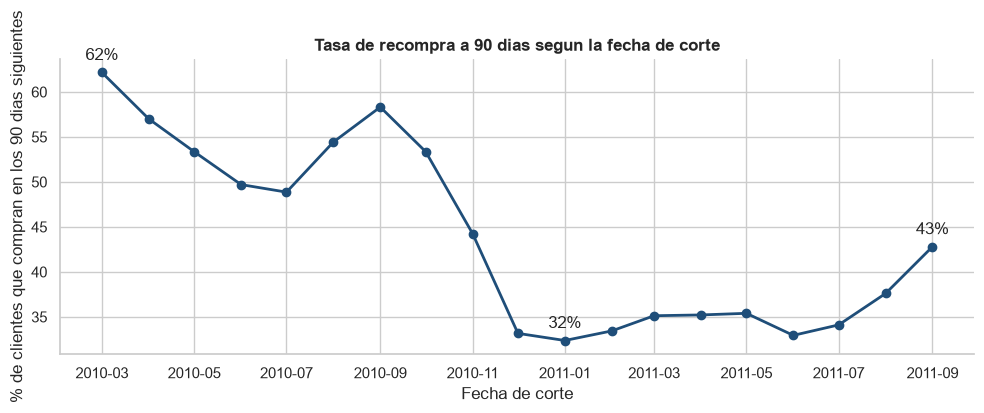

Tasa base global: 41.5% | minimo 32.4% | maximo 62.2%


In [4]:
base = panel.groupby('corte').agg(clientes=('y', 'size'), tasa_recompra=('y', 'mean'))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(base.index, base['tasa_recompra'] * 100, marker='o', color=AZUL, lw=2)
ax.set_title('Tasa de recompra a 90 dias segun la fecha de corte')
ax.set_ylabel('% de clientes que compran en los 90 dias siguientes')
ax.set_xlabel('Fecha de corte')
for x, y in [(base.index[0], base['tasa_recompra'].iloc[0]), (base['tasa_recompra'].idxmin(), base['tasa_recompra'].min()),
             (base.index[-1], base['tasa_recompra'].iloc[-1])]:
    ax.annotate(f'{y:.0%}', (x, y * 100), textcoords='offset points', xytext=(0, 9), ha='center')
plt.tight_layout()
plt.savefig(FIG / '06_01_tasa_base_por_corte.png', dpi=150, bbox_inches='tight')
plt.show()
R['base_min'] = coma(base['tasa_recompra'].min() * 100, 0)
R['base_max'] = coma(base['tasa_recompra'].max() * 100, 0)
R['base_global'] = coma(panel['y'].mean() * 100, 1)
print(f'Tasa base global: {panel["y"].mean():.1%} | minimo {base["tasa_recompra"].min():.1%} | maximo {base["tasa_recompra"].max():.1%}')

**Lectura.** La tasa de recompra **no es constante**: baja a ~@@base_min@@ % para los cortes de invierno (la ventana de 90 días cae en enero-marzo, temporada baja) y sube a ~@@base_max@@ % cuando la ventana incluye octubre-noviembre. Esto tiene dos consecuencias para el modelado: (1) el mes del corte es una variable legítima y (2) **hay que validar hacia adelante en el tiempo**, no mezclando fechas al azar, porque en producción el modelo siempre predice un futuro que no vio.

## 3. División temporal y validación cruzada temporal

Una división aleatoria sería **engañosa**: el mismo cliente aparecería en entrenamiento y en prueba, y un corte de junio ayudaría a "adivinar" uno de julio. Se hace una división **por fechas**:

- **Entrenamiento (con validación cruzada):** cortes de marzo de 2010 a febrero de 2011.
- **Prueba (se usa una sola vez, al final):** cortes de mayo a septiembre de 2011. Sus ventanas de 90 días llegan hasta noviembre de 2011, es decir, **incluyen la temporada alta que el modelo vio solo una vez**. Es una prueba exigente.
- Entre ambos queda un **hueco de ~3 meses** (marzo y abril de 2011) para que la ventana futura de entrenamiento no se solape con la de prueba.

Dentro del entrenamiento se usa **validación cruzada con ventana creciente**: se entrena con el pasado y se valida en un bloque posterior, dejando también un hueco de 90 días entre ambos. Los 4 bloques de validación van de agosto de 2010 a febrero de 2011.

In [5]:
CORTE_FIN_TRAIN = pd.Timestamp('2011-02-01')
CORTE_INI_TEST = pd.Timestamp('2011-05-01')
train = panel[panel['corte'] <= CORTE_FIN_TRAIN].reset_index(drop=True)
test = panel[panel['corte'] >= CORTE_INI_TEST].reset_index(drop=True)

# Bloques de validacion (inicio, fin); el entrenamiento de cada fold usa los cortes cuya ventana termina antes del bloque
BLOQUES = [('2010-08-01', '2010-09-01'), ('2010-10-01', '2010-11-01'),
           ('2010-12-01', '2011-01-01'), ('2011-02-01', '2011-02-01')]
folds = []
for ini, fin in BLOQUES:
    ini, fin = pd.Timestamp(ini), pd.Timestamp(fin)
    idx_tr = np.where(train['corte'] + pd.Timedelta(days=HORIZONTE) <= ini)[0]
    idx_va = np.where((train['corte'] >= ini) & (train['corte'] <= fin))[0]
    folds.append((idx_tr, idx_va))
    assert train.loc[idx_tr, 'corte'].max() + pd.Timedelta(days=HORIZONTE) <= train.loc[idx_va, 'corte'].min()

resumen_folds = pd.DataFrame([{
    'fold': i + 1, 'cortes_entrenamiento': f"{train.loc[a, 'corte'].min():%Y-%m} a {train.loc[a, 'corte'].max():%Y-%m}",
    'filas_entrenamiento': len(a), 'cortes_validacion': f"{train.loc[b, 'corte'].min():%Y-%m} a {train.loc[b, 'corte'].max():%Y-%m}",
    'filas_validacion': len(b), 'tasa_recompra_validacion': train.loc[b, 'y'].mean()} for i, (a, b) in enumerate(folds)])
print(f'Entrenamiento: {len(train):,} filas ({train["y"].mean():.1%} recompra) | Prueba: {len(test):,} filas ({test["y"].mean():.1%} recompra)')
R['n_train'] = f'{len(train):,}'.replace(',', '.')
R['n_test'] = f'{len(test):,}'.replace(',', '.')
R['tasa_train'] = coma(train['y'].mean() * 100)
R['tasa_test'] = coma(test['y'].mean() * 100)
resumen_folds

Entrenamiento: 38,720 filas (46.1% recompra) | Prueba: 25,062 filas (36.7% recompra)


,fold,cortes_entrenamiento,filas_entrenamiento,cortes_validacion,filas_validacion,tasa_recompra_validacion
0,1,2010-03 a 2010-05,6258,2010-08 a 2010-09,6435,0.564
1,2,2010-03 a 2010-07,11893,2010-10 a 2010-11,7451,0.486
2,3,2010-03 a 2010-09,18328,2010-12 a 2011-01,8554,0.328
3,4,2010-03 a 2010-11,25779,2011-02 a 2011-02,4387,0.334


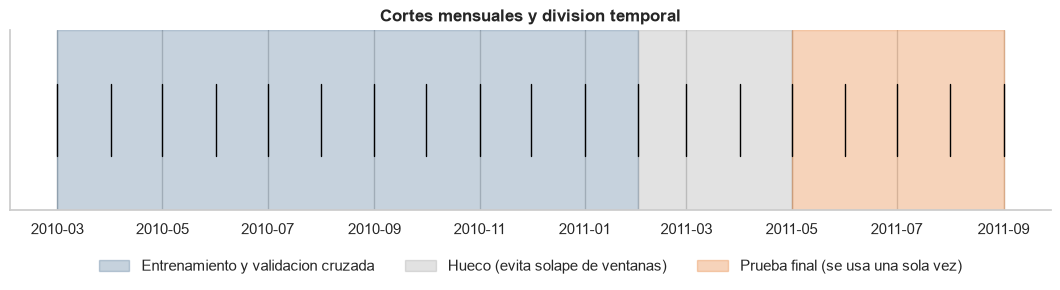

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.axvspan(CORTES[0], CORTE_FIN_TRAIN, color=AZUL, alpha=.25, label='Entrenamiento y validacion cruzada')
ax.axvspan(CORTE_FIN_TRAIN, CORTE_INI_TEST, color=GRIS, alpha=.25, label='Hueco (evita solape de ventanas)')
ax.axvspan(CORTE_INI_TEST, CORTES[-1], color=NARANJA, alpha=.35, label='Prueba final (se usa una sola vez)')
for c in CORTES:
    ax.plot([c, c], [0.3, 0.7], color='black', lw=1)
ax.set_yticks([]); ax.set_ylim(0, 1)
ax.set_title('Cortes mensuales y division temporal')
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.2), ncol=3, frameon=False)
plt.tight_layout()
plt.savefig(FIG / '06_02_esquema_temporal.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Análisis exploratorio orientado al modelo

Antes de modelar se revisa qué variables se relacionan con la recompra **usando solo el entrenamiento** (el conjunto de prueba no se mira).

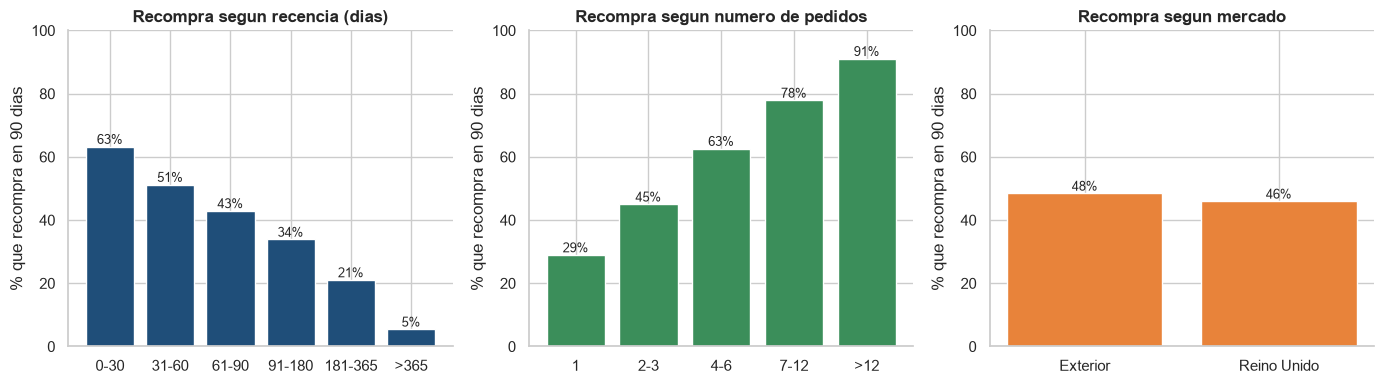

In [7]:
FEATS = ['recencia', 'frecuencia', 'monetario', 'antiguedad', 'ticket_medio', 'lineas_medias', 'unidades_medias',
         'intervalo_medio', 'pedidos_90d', 'gasto_90d', 'pedidos_180d', 'n_productos', 'tasa_devolucion',
         'exterior', 'mes_sin', 'mes_cos']
LOG = [c for c in FEATS if c not in ('exterior', 'mes_sin', 'mes_cos', 'tasa_devolucion')]

fig, axs = plt.subplots(1, 3, figsize=(14, 4))
# 1) recencia (bandas)
b = pd.cut(train['recencia'], [-1, 30, 60, 90, 180, 365, 1000], labels=['0-30', '31-60', '61-90', '91-180', '181-365', '>365'])
t = train.groupby(b, observed=True)['y'].mean() * 100
axs[0].bar(t.index.astype(str), t.values, color=AZUL); axs[0].set_title('Recompra segun recencia (dias)')
# 2) frecuencia (bandas)
b = pd.cut(train['frecuencia'], [0, 1, 3, 6, 12, 1000], labels=['1', '2-3', '4-6', '7-12', '>12'])
t2 = train.groupby(b, observed=True)['y'].mean() * 100
axs[1].bar(t2.index.astype(str), t2.values, color=VERDE); axs[1].set_title('Recompra segun numero de pedidos')
# 3) mercado
t3 = train.groupby(train['exterior'].map({0: 'Reino Unido', 1: 'Exterior'}))['y'].mean() * 100
axs[2].bar(t3.index, t3.values, color=NARANJA); axs[2].set_title('Recompra segun mercado')
for a in axs:
    a.set_ylabel('% que recompra en 90 dias'); a.set_ylim(0, 100)
    for p in a.patches:
        a.annotate(f'{p.get_height():.0f}%', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(FIG / '06_03_eda_recompra_por_variable.png', dpi=150, bbox_inches='tight')
plt.show()
R['rec_0_30'] = coma(t.iloc[0], 0); R['rec_gt365'] = coma(t.iloc[-1], 0)
R['frec_1'] = coma(t2.iloc[0], 0); R['frec_gt12'] = coma(t2.iloc[-1], 0)
R['merc_uk'] = coma(t3['Reino Unido'], 0); R['merc_ext'] = coma(t3['Exterior'], 0)

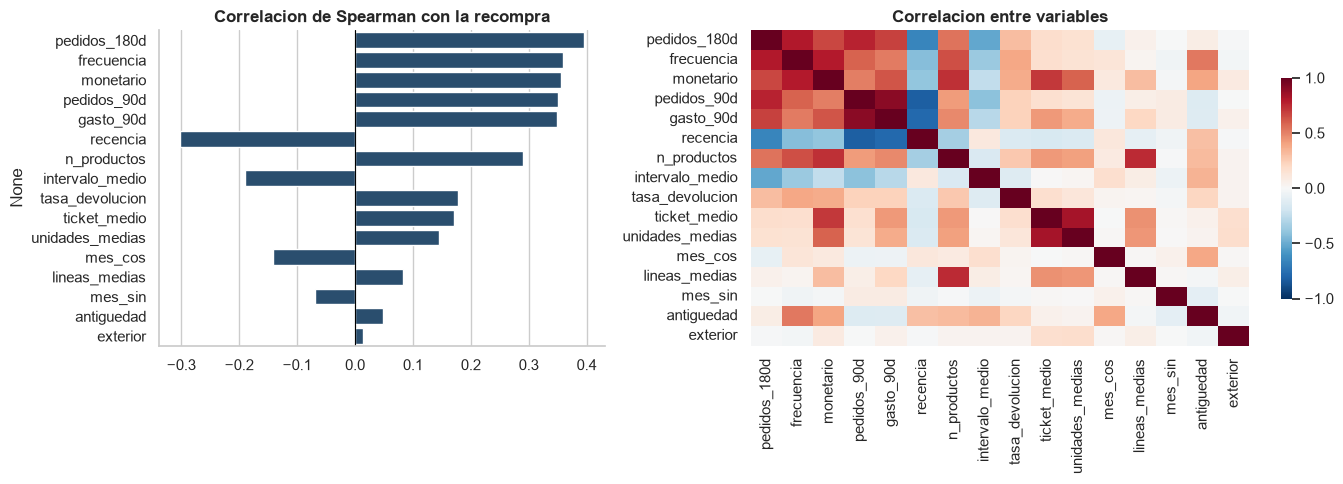

Pares de variables con |Spearman| >= 0,8: [('pedidos_180d', 'frecuencia', np.float64(0.8)), ('pedidos_90d', 'gasto_90d', np.float64(0.9)), ('pedidos_90d', 'recencia', np.float64(-0.82)), ('ticket_medio', 'unidades_medias', np.float64(0.83))]


In [8]:
# Correlacion de Spearman de cada variable con el objetivo (solo entrenamiento) y entre variables
sp = train[FEATS + ['y']].corr(method='spearman')
orden = sp['y'].drop('y').abs().sort_values(ascending=False).index
fig, axs = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1, 1.4]})
sns.barplot(x=sp.loc[orden, 'y'].values, y=orden, color=AZUL, ax=axs[0]); axs[0].set_title('Correlacion de Spearman con la recompra')
axs[0].axvline(0, color='black', lw=.8)
sns.heatmap(sp.loc[orden, orden], cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axs[1], cbar_kws={'shrink': .7})
axs[1].set_title('Correlacion entre variables')
plt.tight_layout()
plt.savefig(FIG / '06_04_correlaciones_modelo.png', dpi=150, bbox_inches='tight')
plt.show()
altas = [(a, b, sp.loc[a, b]) for i, a in enumerate(orden) for b in orden[i + 1:] if abs(sp.loc[a, b]) >= 0.8]
print('Pares de variables con |Spearman| >= 0,8:', [(a, b, round(c, 2)) for a, b, c in altas])
R['top_corr'] = ', '.join(f'`{c}`' for c in orden[:3])
R['n_pares_altos'] = str(len(altas))

**Lectura.**
- La **recencia** separa muy bien: entre quienes compraron en los últimos 30 días recompra ~@@rec_0_30@@ %, y entre quienes llevan más de un año sin comprar ~@@rec_gt365@@ %.
- La **frecuencia** también: los clientes de un solo pedido recompran ~@@frec_1@@ %; los de más de 12 pedidos, ~@@frec_gt12@@ %.
- El mercado casi no separa (Reino Unido ~@@merc_uk@@ %, Exterior ~@@merc_ext@@ %), coherente con la hipótesis H6 del notebook 04 (no hay diferencia relevante en la recompra por mercado).
- Las variables más asociadas con la recompra son @@top_corr@@. Hay @@n_pares_altos@@ pares de variables muy correlacionadas entre sí (|ρ| ≥ 0,8): es esperable porque todas resumen la misma actividad. Esto no perjudica a los árboles y la regresión logística lleva regularización.

## 5. Línea base y tres algoritmos candidatos

Se comparan algoritmos con supuestos y sesgos distintos:

| Modelo | Idea | Supuestos / ventajas | Limitaciones |
|---|---|---|---|
| **Regla de recencia** (línea base) | Ordena por "más reciente = más probable" | Sin entrenamiento; fácil de explicar | Ignora frecuencia, ritmo y estacionalidad |
| **Regresión logística** | Combinación lineal de variables → probabilidad | Interpretable; probabilidades bien calibradas; rápida | Asume efectos lineales (tras log) y sin interacciones |
| **Random Forest** | Muchos árboles sobre muestras aleatorias | Capta no linealidades e interacciones; robusto a atípicos | Menos interpretable; probabilidades menos finas |
| **Gradient Boosting (HistGradientBoosting)** | Árboles encadenados que corrigen errores | Suele ser el más preciso en datos tabulares; maneja vacíos | Más hiperparámetros; riesgo de sobreajuste |

Todo el preprocesamiento (imputación, logaritmo, estandarización) vive **dentro del `Pipeline`** y se ajusta solo con los datos de entrenamiento de cada fold, para que la validación no se contamine.

In [9]:
def prep_lineal():
    """Imputa vacios, aplica log1p a variables sesgadas y estandariza (para la regresion logistica)."""
    log = Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)),
                    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                    ('esc', StandardScaler())])
    otras = Pipeline([('imp', SimpleImputer(strategy='median')), ('esc', StandardScaler())])
    return ColumnTransformer([('log', log, LOG), ('otras', otras, [c for c in FEATS if c not in LOG])])


def prep_arbol():
    """Los arboles no necesitan escalar; solo imputar los vacios (intervalo_medio de clientes de un pedido)."""
    return ColumnTransformer([('imp', SimpleImputer(strategy='median', add_indicator=True), FEATS)])


def hacer(nombre, **params):
    if nombre == 'Regresion logistica':
        m = Pipeline([('prep', prep_lineal()), ('m', LogisticRegression(max_iter=3000, **params))])
    elif nombre == 'Random Forest':
        m = Pipeline([('prep', prep_arbol()), ('m', RandomForestClassifier(
            **{'n_estimators': 300, 'min_samples_leaf': 20, 'n_jobs': -1, 'random_state': SEMILLA, **params}))])
    else:   # Gradient Boosting: maneja vacios sin imputar
        m = Pipeline([('prep', ColumnTransformer([('pasa', 'passthrough', FEATS)])),
                      ('m', HistGradientBoostingClassifier(random_state=SEMILLA, **params))])
    return m


def evaluar_cv(modelo, X, y, folds):
    """Entrena en el pasado de cada fold y valida en el bloque posterior. Devuelve metricas y predicciones fuera de muestra."""
    filas, oof = [], np.full(len(X), np.nan)
    for i, (a, b) in enumerate(folds):
        m = clone(modelo).fit(X.iloc[a], y.iloc[a])
        p = m.predict_proba(X.iloc[b])[:, 1]
        oof[b] = p
        filas.append({'fold': i + 1, 'pr_auc': average_precision_score(y.iloc[b], p), 'roc_auc': roc_auc_score(y.iloc[b], p)})
    return pd.DataFrame(filas), oof


Xtr, ytr = train[FEATS], train['y']
Xte, yte = test[FEATS], test['y']

# Linea base: la recencia como puntaje (menor recencia = mayor probabilidad)
base_cv = pd.DataFrame([{'fold': i + 1,
                         'pr_auc': average_precision_score(ytr.iloc[b], -Xtr['recencia'].iloc[b]),
                         'roc_auc': roc_auc_score(ytr.iloc[b], -Xtr['recencia'].iloc[b])} for i, (a, b) in enumerate(folds)])
cv_pred, oof_pred = {}, {}
cv_pred['Regla de recencia (base)'] = base_cv
for nombre in ['Regresion logistica', 'Random Forest', 'Gradient Boosting']:
    cv_pred[nombre], oof_pred[nombre] = evaluar_cv(hacer(nombre), Xtr, ytr, folds)

cv_defecto = pd.DataFrame({n: {'PR-AUC (media)': d['pr_auc'].mean(), 'PR-AUC (desv.)': d['pr_auc'].std(),
                               'ROC-AUC (media)': d['roc_auc'].mean(), 'ROC-AUC (desv.)': d['roc_auc'].std()}
                           for n, d in cv_pred.items()}).T
cv_defecto

,PR-AUC (media),PR-AUC (desv.),ROC-AUC (media),ROC-AUC (desv.)
Regla de recencia (base),0.588,0.084,0.685,0.032
Regresion logistica,0.725,0.050,0.757,0.032
Random Forest,0.723,0.055,0.756,0.030
Gradient Boosting,0.714,0.055,0.745,0.031


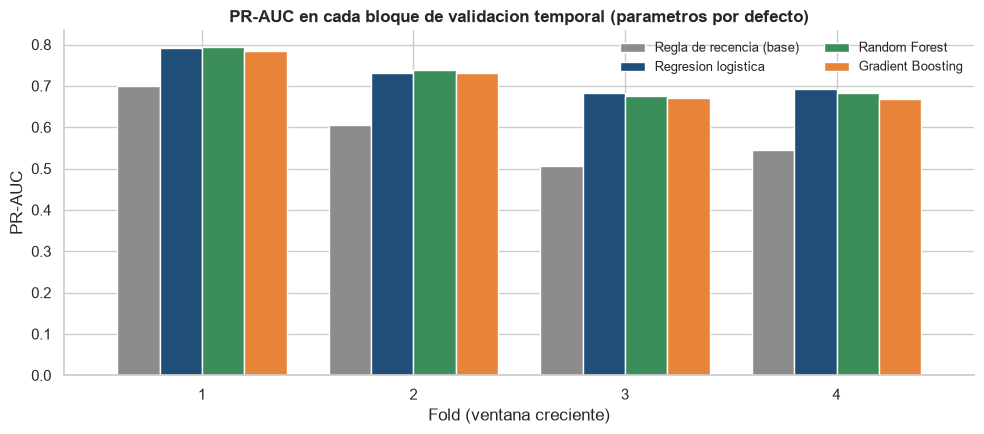

,Regla de recencia (base),Regresion logistica,Random Forest,Gradient Boosting
fold,,,,
1,0.699,0.792,0.794,0.785
2,0.605,0.732,0.739,0.730
3,0.507,0.683,0.676,0.672
4,0.544,0.692,0.684,0.668


In [10]:
cv_pred_detalle = pd.concat({n: d.set_index('fold')['pr_auc'] for n, d in cv_pred.items()}, axis=1)
fig, ax = plt.subplots(figsize=(10, 4.5))
cv_pred_detalle.plot(kind='bar', ax=ax, color=[GRIS, AZUL, VERDE, NARANJA], width=.8)
ax.set_title('PR-AUC en cada bloque de validacion temporal (parametros por defecto)')
ax.set_xlabel('Fold (ventana creciente)'); ax.set_ylabel('PR-AUC'); ax.legend(frameon=False, ncol=2, fontsize=9)
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(FIG / '06_05_comparacion_cv_defecto.png', dpi=150, bbox_inches='tight')
plt.show()
cv_pred_detalle.round(3)

## 6. Ajuste de hiperparámetros

Se usa **búsqueda aleatoria** (`RandomizedSearchCV`) con los **mismos folds temporales** y PR-AUC como criterio. La búsqueda aleatoria explora el espacio mucho más rápido que una rejilla completa y suele encontrar combinaciones igual de buenas. Para cada modelo se exploran los parámetros que más controlan el sobreajuste:

- **Regresión logística:** fuerza de regularización `C` (L2).
- **Random Forest:** profundidad, hoja mínima, número de árboles y variables por división.
- **Gradient Boosting:** tasa de aprendizaje, nodos por árbol, hoja mínima, regularización L2 y número de iteraciones.

In [11]:
espacios = {
    'Regresion logistica': (hacer('Regresion logistica'), {'m__C': loguniform(1e-3, 1e2)}, 12),
    'Random Forest': (hacer('Random Forest'), {'m__n_estimators': randint(150, 500), 'm__max_depth': [6, 8, 12, 16, None],
                                               'm__min_samples_leaf': randint(5, 120), 'm__max_features': ['sqrt', 0.5, 0.8]}, 14),
    'Gradient Boosting': (hacer('Gradient Boosting'), {'m__learning_rate': loguniform(0.02, 0.3), 'm__max_leaf_nodes': randint(6, 64),
                                                       'm__min_samples_leaf': randint(20, 250), 'm__l2_regularization': loguniform(1e-3, 10),
                                                       'm__max_iter': randint(80, 400)}, 20),
}
mejores, busquedas = {}, {}
for nombre, (pipe, espacio, n_iter) in espacios.items():
    bus = RandomizedSearchCV(pipe, espacio, n_iter=n_iter, scoring='average_precision', cv=folds,
                             random_state=SEMILLA, n_jobs=-1, refit=False)
    bus.fit(Xtr, ytr)
    busquedas[nombre] = bus
    mejores[nombre] = {k.replace('m__', ''): v for k, v in bus.best_params_.items()}
    print(f'{nombre:<20} mejor PR-AUC medio en CV = {bus.best_score_:.4f}  |  {mejores[nombre]}')

Regresion logistica  mejor PR-AUC medio en CV = 0.7249  |  {'C': np.float64(0.006026889128682512)}


Random Forest        mejor PR-AUC medio en CV = 0.7268  |  {'max_depth': 6, 'max_features': 0.8, 'min_samples_leaf': 22, 'n_estimators': 238}


Gradient Boosting    mejor PR-AUC medio en CV = 0.7267  |  {'l2_regularization': np.float64(4.337920697490942), 'learning_rate': np.float64(0.04030685101059539), 'max_iter': 81, 'max_leaf_nodes': 11, 'min_samples_leaf': 73}


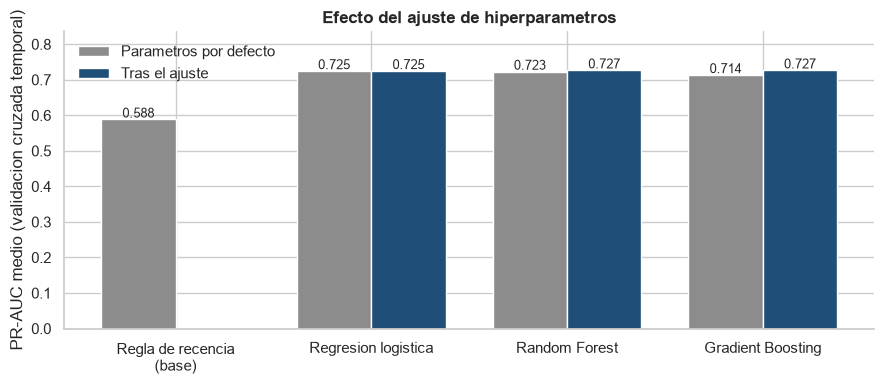

Modelo elegido por PR-AUC en validacion cruzada: Random Forest


,PR-AUC defecto,PR-AUC ajustado,ROC-AUC ajustado,Desv. PR-AUC
Regla de recencia (base),0.588,NaN,0.685,0.084
Regresion logistica,0.725,0.725,0.757,0.051
Random Forest,0.723,0.727,0.759,0.053
Gradient Boosting,0.714,0.727,0.760,0.055


In [12]:
# Resultados tras el ajuste: media y desviacion entre folds, y comparacion con los parametros por defecto
cv_ajustado, oof_ajustado = {}, {}
for nombre in ['Regresion logistica', 'Random Forest', 'Gradient Boosting']:
    cv_ajustado[nombre], oof_ajustado[nombre] = evaluar_cv(hacer(nombre, **mejores[nombre]), Xtr, ytr, folds)

comparacion = pd.DataFrame({
    'Regla de recencia (base)': {'PR-AUC defecto': cv_pred['Regla de recencia (base)']['pr_auc'].mean(), 'PR-AUC ajustado': np.nan,
                                 'ROC-AUC ajustado': cv_pred['Regla de recencia (base)']['roc_auc'].mean(), 'Desv. PR-AUC': cv_pred['Regla de recencia (base)']['pr_auc'].std()},
    **{n: {'PR-AUC defecto': cv_pred[n]['pr_auc'].mean(), 'PR-AUC ajustado': cv_ajustado[n]['pr_auc'].mean(),
           'ROC-AUC ajustado': cv_ajustado[n]['roc_auc'].mean(), 'Desv. PR-AUC': cv_ajustado[n]['pr_auc'].std()}
       for n in cv_ajustado}}).T
comparacion.to_csv(SALIDA / 'comparacion_cv.csv')

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(comparacion)); w = .38
ax.bar(x - w / 2, comparacion['PR-AUC defecto'], w, color=GRIS, label='Parametros por defecto')
ax.bar(x + w / 2, comparacion['PR-AUC ajustado'], w, color=AZUL, label='Tras el ajuste')
for i, (d, a) in enumerate(zip(comparacion['PR-AUC defecto'], comparacion['PR-AUC ajustado'])):
    ax.text(i - w / 2, d + .005, f'{d:.3f}', ha='center', fontsize=9)
    if not np.isnan(a): ax.text(i + w / 2, a + .005, f'{a:.3f}', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([t.replace(' (base)', '\n(base)') for t in comparacion.index])
ax.set_ylabel('PR-AUC medio (validacion cruzada temporal)'); ax.set_title('Efecto del ajuste de hiperparametros'); ax.legend(frameon=False)
ax.set_ylim(0, comparacion[['PR-AUC defecto', 'PR-AUC ajustado']].max().max() * 1.15)
plt.tight_layout(); plt.savefig(FIG / '06_06_comparacion_cv_ajustada.png', dpi=150, bbox_inches='tight'); plt.show()

ganador = comparacion.drop(index='Regla de recencia (base)')['PR-AUC ajustado'].idxmax()
R['pr_base'] = coma(comparacion.loc['Regla de recencia (base)', 'PR-AUC defecto'], 3)
for k, n in {'lr': 'Regresion logistica', 'rf': 'Random Forest', 'gb': 'Gradient Boosting'}.items():
    R[f'cv_{k}'] = coma(comparacion.loc[n, 'PR-AUC ajustado'], 3)
    R[f'cv_{k}_def'] = coma(comparacion.loc[n, 'PR-AUC defecto'], 3)
    R[f'sd_{k}'] = coma(comparacion.loc[n, 'Desv. PR-AUC'], 3)
R['ganador'] = ganador
print('Modelo elegido por PR-AUC en validacion cruzada:', ganador)
comparacion.round(3)

**Decisión.** El modelo se elige **solo con la validación cruzada del entrenamiento**, nunca con la prueba final. Resultado: gana **@@ganador@@** (PR-AUC @@cv_rf@@), pero está **prácticamente empatado** con Gradient Boosting (@@cv_gb@@) y con la regresión logística (@@cv_lr@@); la línea base de recencia obtiene @@pr_base@@.

Observaciones:
- Los tres algoritmos superan con claridad la regla de recencia: aprender de varias variables agrega información (ritmo propio, número de pedidos recientes, gasto).
- La diferencia entre los tres modelos es **mucho menor que la variación entre folds** (desviación de ~@@sd_gb@@): con estos datos, los algoritmos complejos casi no mejoran a una regresión logística. Que la mejor regresión logística use una regularización muy fuerte (`C` ≈ 0,006) y el mejor Random Forest sea poco profundo (`max_depth` = 6) indica que **la señal es simple**: se aprende con pocas reglas.
- El ajuste de hiperparámetros sube la PR-AUC solo de @@cv_gb_def@@ a @@cv_gb@@ en Gradient Boosting y casi nada en los otros dos: el problema está limitado por la información disponible, no por el algoritmo. Si se priorizara la explicabilidad, la regresión logística sería una alternativa casi igual de buena.

## 7. Umbral de decisión

Con la probabilidad se necesita decidir "¿intervenimos o no?". El umbral se elige con las **predicciones fuera de muestra de la validación cruzada** (nunca con la prueba): el que maximiza el F1. Como el costo de una campaña y el beneficio de una venta no se conocen con precisión, también se reporta el desempeño **por ranking** (captura en el 30 % superior), que no depende de un umbral.

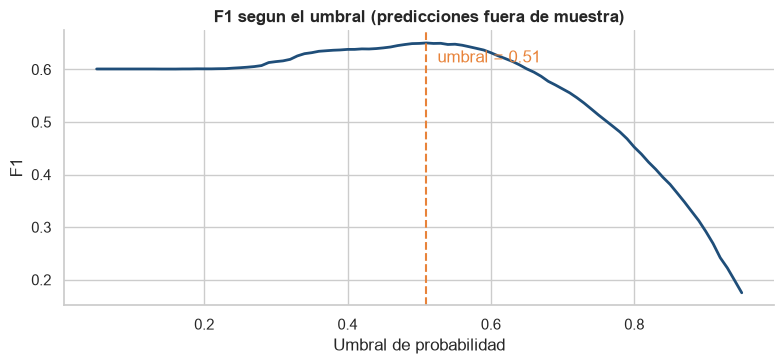

Umbral elegido: 0.51  (F1 fuera de muestra = 0.650)


In [13]:
oof = oof_ajustado[ganador]
mascara = ~np.isnan(oof)
y_oof = ytr.values[mascara]; p_oof = oof[mascara]
umbrales = np.linspace(0.05, 0.95, 91)
f1s = [f1_score(y_oof, p_oof >= u) for u in umbrales]
UMBRAL = float(umbrales[int(np.argmax(f1s))])

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(umbrales, f1s, color=AZUL, lw=2)
ax.axvline(UMBRAL, color=NARANJA, ls='--'); ax.set_title('F1 segun el umbral (predicciones fuera de muestra)')
ax.set_xlabel('Umbral de probabilidad'); ax.set_ylabel('F1')
ax.annotate(f'umbral = {UMBRAL:.2f}', (UMBRAL, max(f1s)), textcoords='offset points', xytext=(8, -14), color=NARANJA)
plt.tight_layout(); plt.savefig(FIG / '06_07_umbral_f1.png', dpi=150, bbox_inches='tight'); plt.show()
R['umbral'] = coma(UMBRAL, 2)
R['f1_cv'] = coma(max(f1s), 3)
print(f'Umbral elegido: {UMBRAL:.2f}  (F1 fuera de muestra = {max(f1s):.3f})')

## 8. Evaluación final en el periodo de prueba

Aquí **por primera y única vez** se usa la prueba (cortes de mayo a septiembre de 2011). El modelo se reentrena con todo el entrenamiento y se evalúa con el umbral ya fijado.

In [14]:
final = hacer(ganador, **mejores[ganador]).fit(Xtr, ytr)
p_te = final.predict_proba(Xte)[:, 1]
pred = (p_te >= UMBRAL).astype(int)

# Referencias en prueba: regla de recencia y modelo por defecto de la misma familia
p_base = -Xte['recencia'].values
res = {
    'Regla de recencia (base)': {'PR-AUC': average_precision_score(yte, p_base), 'ROC-AUC': roc_auc_score(yte, p_base)},
    ganador: {'PR-AUC': average_precision_score(yte, p_te), 'ROC-AUC': roc_auc_score(yte, p_te),
              'Precision': precision_score(yte, pred), 'Recall': recall_score(yte, pred), 'F1': f1_score(yte, pred),
              'Brier': brier_score_loss(yte, p_te)}}
metricas = pd.DataFrame(res).T
metricas['Tasa base en prueba'] = yte.mean()
metricas.to_csv(SALIDA / 'metricas_test.csv')
tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
print(metricas.round(3).to_string())
print(f'\nMatriz de confusion con umbral {UMBRAL:.2f}:  VP={tp:,}  FP={fp:,}  FN={fn:,}  VN={tn:,}')
for k, v in {'pr_test': res[ganador]['PR-AUC'], 'roc_test': res[ganador]['ROC-AUC'], 'prec_test': res[ganador]['Precision'],
             'rec_test': res[ganador]['Recall'], 'f1_test': res[ganador]['F1'], 'brier_test': res[ganador]['Brier'],
             'pr_base_test': res['Regla de recencia (base)']['PR-AUC'], 'roc_base_test': res['Regla de recencia (base)']['ROC-AUC']}.items():
    R[k] = coma(v, 3)
R['vp'], R['fp'], R['fn'], R['vn'] = [f'{v:,}'.replace(',', '.') for v in (tp, fp, fn, tn)]
R['mejora_pr'] = coma((res[ganador]['PR-AUC'] / res['Regla de recencia (base)']['PR-AUC'] - 1) * 100, 0)

                          PR-AUC  ROC-AUC  Precision  Recall    F1  Brier  Tasa base en prueba
Regla de recencia (base)   0.623    0.765        NaN     NaN   NaN    NaN                0.367
Random Forest              0.737    0.800      0.624   0.692 0.656  0.190                0.367

Matriz de confusion con umbral 0.51:  VP=6,353  FP=3,821  FN=2,833  VN=12,055


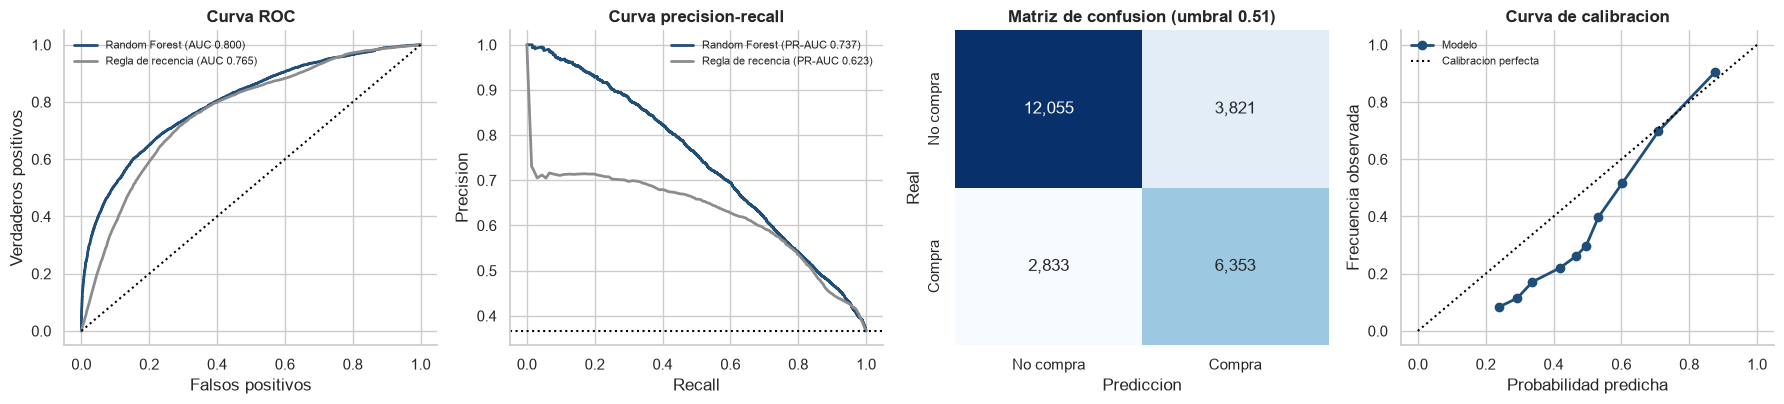

Probabilidad media predicha 0.497 vs. tasa observada 0.367


In [15]:
fig, axs = plt.subplots(1, 4, figsize=(18, 4.2))
fpr, tpr, _ = roc_curve(yte, p_te); fb, tb, _ = roc_curve(yte, p_base)
axs[0].plot(fpr, tpr, color=AZUL, lw=2, label=f'{ganador} (AUC {res[ganador]["ROC-AUC"]:.3f})')
axs[0].plot(fb, tb, color=GRIS, lw=2, label=f'Regla de recencia (AUC {res["Regla de recencia (base)"]["ROC-AUC"]:.3f})')
axs[0].plot([0, 1], [0, 1], ':', color='black'); axs[0].set_title('Curva ROC'); axs[0].set_xlabel('Falsos positivos'); axs[0].set_ylabel('Verdaderos positivos'); axs[0].legend(frameon=False, fontsize=8)
pr, rc, _ = precision_recall_curve(yte, p_te); pb, rb, _ = precision_recall_curve(yte, p_base)
axs[1].plot(rc, pr, color=AZUL, lw=2, label=f'{ganador} (PR-AUC {res[ganador]["PR-AUC"]:.3f})')
axs[1].plot(rb, pb, color=GRIS, lw=2, label=f'Regla de recencia (PR-AUC {res["Regla de recencia (base)"]["PR-AUC"]:.3f})')
axs[1].axhline(yte.mean(), ls=':', color='black'); axs[1].set_title('Curva precision-recall'); axs[1].set_xlabel('Recall'); axs[1].set_ylabel('Precision'); axs[1].legend(frameon=False, fontsize=8)
sns.heatmap(confusion_matrix(yte, pred), annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axs[2],
            xticklabels=['No compra', 'Compra'], yticklabels=['No compra', 'Compra'])
axs[2].set_title(f'Matriz de confusion (umbral {UMBRAL:.2f})'); axs[2].set_xlabel('Prediccion'); axs[2].set_ylabel('Real')
fr, mp = calibration_curve(yte, p_te, n_bins=10, strategy='quantile')
axs[3].plot(mp, fr, marker='o', color=AZUL, lw=2, label='Modelo'); axs[3].plot([0, 1], [0, 1], ':', color='black', label='Calibracion perfecta')
axs[3].set_title('Curva de calibracion'); axs[3].set_xlabel('Probabilidad predicha'); axs[3].set_ylabel('Frecuencia observada'); axs[3].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / '06_08_evaluacion_test.png', dpi=150, bbox_inches='tight'); plt.show()
R['sesgo_calibracion'] = coma((p_te.mean() - yte.mean()) * 100, 1)
print(f'Probabilidad media predicha {p_te.mean():.3f} vs. tasa observada {yte.mean():.3f}')

In [16]:
# Incertidumbre: bootstrap por CLIENTE (un mismo cliente aparece en varios cortes, por eso se remuestrean clientes, no filas)
rng = np.random.default_rng(SEMILLA)
clientes = test['cliente_key'].values
idx_por_cliente = pd.Series(np.arange(len(test))).groupby(clientes).apply(np.array)
llaves = idx_por_cliente.index.values
boot = []
for _ in range(300):
    muestra = rng.choice(llaves, size=len(llaves), replace=True)
    idx = np.concatenate(idx_por_cliente.loc[muestra].values)
    boot.append((average_precision_score(yte.values[idx], p_te[idx]), roc_auc_score(yte.values[idx], p_te[idx])))
boot = np.array(boot)
ic_pr = np.percentile(boot[:, 0], [2.5, 97.5]); ic_roc = np.percentile(boot[:, 1], [2.5, 97.5])
R['ic_pr'] = f'{coma(ic_pr[0], 3)} a {coma(ic_pr[1], 3)}'
R['ic_roc'] = f'{coma(ic_roc[0], 3)} a {coma(ic_roc[1], 3)}'
print(f'PR-AUC {res[ganador]["PR-AUC"]:.3f}  IC95% [{ic_pr[0]:.3f}, {ic_pr[1]:.3f}]')
print(f'ROC-AUC {res[ganador]["ROC-AUC"]:.3f}  IC95% [{ic_roc[0]:.3f}, {ic_roc[1]:.3f}]')

PR-AUC 0.737  IC95% [0.722, 0.750]
ROC-AUC 0.800  IC95% [0.790, 0.808]


**Lectura de la evaluación final**

- En el periodo de prueba, el modelo obtiene **PR-AUC @@pr_test@@** (IC 95 %: @@ic_pr@@) y **ROC-AUC @@roc_test@@** (IC 95 %: @@ic_roc@@), frente a @@pr_base_test@@ y @@roc_base_test@@ de la regla de recencia: **@@mejora_pr@@ % más de PR-AUC** que la regla sin aprendizaje.
- Con el umbral de @@umbral@@ el modelo logra **precisión @@prec_test@@, recall @@rec_test@@ y F1 @@f1_test@@**. La matriz muestra @@vp@@ aciertos de compra, @@fp@@ falsos positivos, @@fn@@ compras no anticipadas y @@vn@@ no compras bien identificadas.
- **Calibración:** la probabilidad media predicha difiere de la tasa observada en @@sesgo_calibracion@@ puntos porcentuales. La tasa base de prueba (@@tasa_test@@ %) es menor que la de entrenamiento (@@tasa_train@@ %) porque el entrenamiento contiene los meses de temporada alta de 2010: el modelo tiende a ser **algo optimista** cuando la temporada es más floja. Es un aviso de **deriva**, y la razón para recalibrar con datos recientes al usarlo.
- La separación (ROC-AUC alrededor de 0,8) es buena pero **no perfecta**: el comportamiento de compra de mayoristas depende de factores que no están en los datos (precios de la competencia, inventario, relaciones comerciales).

## 9. Estabilidad: ¿el desempeño se sostiene en cada mes de prueba?

Un solo número puede esconder meses malos. Se mide por separado en cada corte de prueba (mayo a septiembre de 2011).

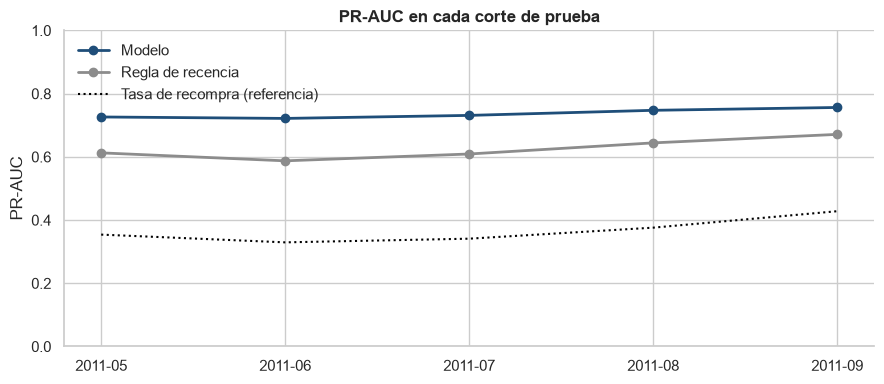

,corte,clientes,tasa_recompra,pr_auc,roc_auc,pr_auc_base
0,2011-05,4797,0.354,0.726,0.795,0.613
1,2011-06,4908,0.329,0.722,0.808,0.587
2,2011-07,5016,0.341,0.731,0.809,0.609
3,2011-08,5117,0.376,0.747,0.804,0.644
4,2011-09,5224,0.428,0.756,0.780,0.671


In [17]:
filas = []
for c, g in test.assign(p=p_te).groupby('corte'):
    filas.append({'corte': f'{c:%Y-%m}', 'clientes': len(g), 'tasa_recompra': g['y'].mean(),
                  'pr_auc': average_precision_score(g['y'], g['p']), 'roc_auc': roc_auc_score(g['y'], g['p']),
                  'pr_auc_base': average_precision_score(g['y'], -g['recencia'])})
estab = pd.DataFrame(filas)
estab.to_csv(SALIDA / 'estabilidad_por_corte.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(estab['corte'], estab['pr_auc'], marker='o', color=AZUL, lw=2, label='Modelo')
ax.plot(estab['corte'], estab['pr_auc_base'], marker='o', color=GRIS, lw=2, label='Regla de recencia')
ax.plot(estab['corte'], estab['tasa_recompra'], ls=':', color='black', label='Tasa de recompra (referencia)')
ax.set_ylim(0, 1); ax.set_title('PR-AUC en cada corte de prueba'); ax.set_ylabel('PR-AUC'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / '06_09_estabilidad_por_corte.png', dpi=150, bbox_inches='tight'); plt.show()
R['est_min'] = coma(estab['pr_auc'].min(), 3); R['est_max'] = coma(estab['pr_auc'].max(), 3)
R['gana_todos'] = 'en los 5 cortes' if (estab['pr_auc'] > estab['pr_auc_base']).all() else f"en {(estab['pr_auc'] > estab['pr_auc_base']).sum()} de {len(estab)} cortes"
estab.round(3)

**Lectura.** El PR-AUC por corte va de @@est_min@@ a @@est_max@@, y el modelo supera a la regla de recencia **@@gana_todos@@**. La ventaja es consistente, aunque su tamaño varía con la temporada.

## 10. Interpretación del modelo

Un modelo que no se puede explicar no se usa. Se responde en tres niveles: **qué variables importan** (importancia por permutación), **cómo influyen** (dependencia parcial) y **a quién le falla** (segmentos y equidad).

### 10.1 Importancia por permutación

Se baraja una variable a la vez en la **prueba** y se mide cuánto cae la PR-AUC. Una caída grande significa que el modelo depende de esa variable. Se prefiere a la importancia interna de los árboles porque no favorece variables con muchos valores distintos.

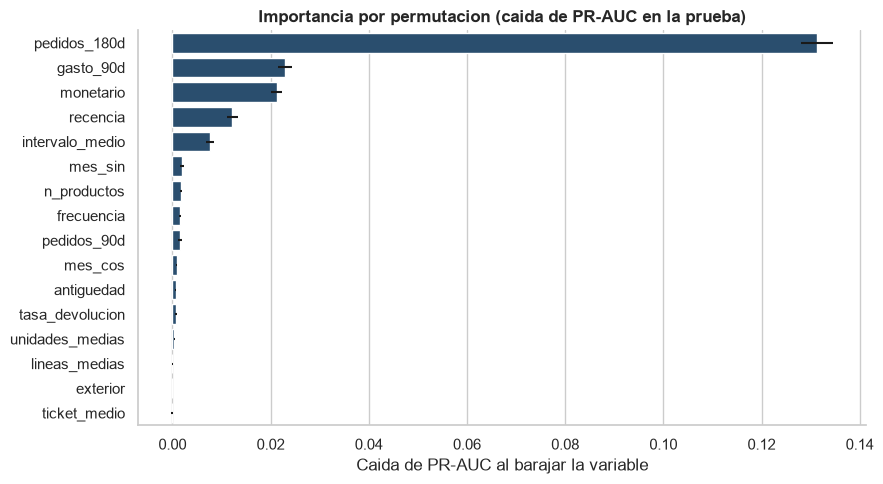

,variable,caida_pr_auc,desv
0,pedidos_180d,0.131,0.003
1,gasto_90d,0.023,0.001
2,monetario,0.021,0.001
3,recencia,0.012,0.001
4,intervalo_medio,0.008,0.001
5,mes_sin,0.002,0.000
6,n_productos,0.002,0.000
7,frecuencia,0.002,0.000
8,pedidos_90d,0.002,0.000
9,mes_cos,0.001,0.000


In [18]:
perm = permutation_importance(final, Xte, yte, scoring='average_precision', n_repeats=10, random_state=SEMILLA, n_jobs=-1)
imp = (pd.DataFrame({'variable': FEATS, 'caida_pr_auc': perm.importances_mean, 'desv': perm.importances_std})
       .sort_values('caida_pr_auc', ascending=False).reset_index(drop=True))
imp.to_csv(SALIDA / 'importancia_permutacion.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=imp, y='variable', x='caida_pr_auc', color=AZUL, ax=ax, xerr=imp['desv'])
ax.set_title('Importancia por permutacion (caida de PR-AUC en la prueba)'); ax.set_xlabel('Caida de PR-AUC al barajar la variable'); ax.set_ylabel('')
plt.tight_layout(); plt.savefig(FIG / '06_10_importancia_permutacion.png', dpi=150, bbox_inches='tight'); plt.show()
R['imp1'], R['imp2'], R['imp3'] = [f'`{v}`' for v in imp['variable'][:3]]
R['imp1_v'] = coma(imp['caida_pr_auc'][0], 3); R['imp2_v'] = coma(imp['caida_pr_auc'][1], 3); R['imp3_v'] = coma(imp['caida_pr_auc'][2], 3)
R['imp_ultimas'] = ', '.join(f'`{v}`' for v in imp['variable'][-3:])
imp.round(4)

### 10.2 Dependencia parcial

Muestra cómo cambia la probabilidad predicha al variar **una** variable, promediando sobre el resto. Es la forma de ver la "forma" del efecto (si es lineal, si hay umbrales, etc.).

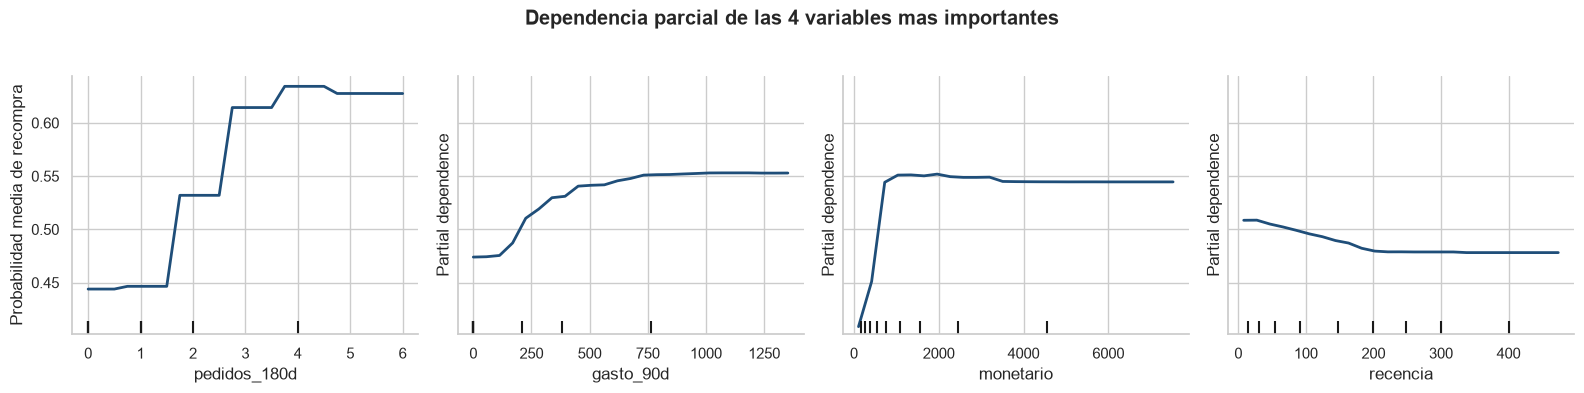

In [19]:
top4 = list(imp['variable'][:4])
muestra = Xte.sample(4000, random_state=SEMILLA).astype(float)   # PDP necesita columnas float
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
PartialDependenceDisplay.from_estimator(final, muestra, top4, kind='average', grid_resolution=25, ax=axs, line_kw={'color': AZUL, 'lw': 2})
axs[0].set_ylabel('Probabilidad media de recompra')
fig.suptitle('Dependencia parcial de las 4 variables mas importantes', fontweight='bold', y=1.03)
plt.tight_layout(); plt.savefig(FIG / '06_11_dependencia_parcial.png', dpi=150, bbox_inches='tight'); plt.show()

**Lectura.** Domina `pedidos_180d` (número de pedidos en los últimos 180 días): al barajarla la PR-AUC cae @@imp1_v@@, frente a @@imp2_v@@ de @@imp2@@ y @@imp3_v@@ de @@imp3@@. Es decir, el modelo se apoya sobre todo en **cuántas veces compró el cliente hace poco**, y en segundo plano en cuánto gastó. Un matiz importante: varias variables miden casi lo mismo (por ejemplo `pedidos_90d`, `frecuencia` y `recencia` están muy correlacionadas con `pedidos_180d`), y cuando una se baraja las demás **la reemplazan en parte**. Por eso la importancia por permutación de las variables "gemelas" se ve baja aunque sí contengan señal; las menos útiles son @@imp_ultimas@@.

Las curvas de dependencia parcial muestran la lógica de negocio: la probabilidad **sube a escalones con los pedidos recientes** (de ~0,44 sin pedidos a ~0,63 con 4 o más), **crece y se satura con el gasto de los últimos 90 días** y con el gasto histórico (a partir de ~£700 ya no sube más) y **baja con la recencia** (cuantos más días sin comprar, menos probable). El modelo aprendió algo sensato, no una coincidencia.

### 10.3 ¿Cuánto depende el modelo de la estacionalidad y de la actividad reciente?

Se entrenan versiones **sin** ciertas variables para ver qué tan frágil es el modelo. Esto es una **ablación**: no se usa para elegir modelo (la elección ya está hecha), sino para entenderlo.

In [20]:
filas = []
grupos = {'Modelo completo': [], 'Sin estacionalidad (mes)': ['mes_sin', 'mes_cos'],
          'Sin actividad reciente (90d/180d)': ['pedidos_90d', 'gasto_90d', 'pedidos_180d'],
          'Sin RFM basico (recencia, frecuencia, monetario)': ['recencia', 'frecuencia', 'monetario']}
FEATS_ORIG, LOG_ORIG = list(FEATS), list(LOG)
for nombre, quitar in grupos.items():
    FEATS[:] = [c for c in FEATS_ORIG if c not in quitar]
    LOG[:] = [c for c in LOG_ORIG if c not in quitar]
    cv_, _ = evaluar_cv(hacer(ganador, **mejores[ganador]), train[FEATS], ytr, folds)
    m = hacer(ganador, **mejores[ganador]).fit(train[FEATS], ytr)
    p = m.predict_proba(test[FEATS])[:, 1]
    filas.append({'version': nombre, 'PR-AUC (validacion cruzada)': cv_['pr_auc'].mean(), 'PR-AUC (prueba)': average_precision_score(yte, p),
                  'ROC-AUC (prueba)': roc_auc_score(yte, p)})
FEATS[:] = FEATS_ORIG; LOG[:] = LOG_ORIG                       # se restauran las listas originales
abl = pd.DataFrame(filas).set_index('version')
abl.to_csv(SALIDA / 'ablacion.csv')
R['abl_mes'] = coma(abl.loc['Sin estacionalidad (mes)', 'PR-AUC (prueba)'], 3)
R['abl_reciente'] = coma(abl.loc['Sin actividad reciente (90d/180d)', 'PR-AUC (prueba)'], 3)
R['abl_rfm'] = coma(abl.loc['Sin RFM basico (recencia, frecuencia, monetario)', 'PR-AUC (prueba)'], 3)
R['abl_full'] = coma(abl.loc['Modelo completo', 'PR-AUC (prueba)'], 3)
abl.round(3)

,PR-AUC (validacion cruzada),PR-AUC (prueba),ROC-AUC (prueba)
version,,,
Modelo completo,0.727,0.737,0.800
Sin estacionalidad (mes),0.726,0.739,0.803
Sin actividad reciente (90d/180d),0.725,0.726,0.788
"Sin RFM basico (recencia, frecuencia, monetario)",0.721,0.735,0.797


**Lectura.** El modelo completo obtiene PR-AUC de @@abl_full@@ en la prueba. Quitar el mes (estacionalidad) lo deja en @@abl_mes@@, es decir, **no ayuda**: con un solo ciclo anual en el entrenamiento el modelo no puede aprender bien la temporada, y la actividad reciente ya refleja en parte la estacionalidad. Quitar el RFM básico lo deja en @@abl_rfm@@ (casi igual, porque `pedidos_180d`, `gasto_90d` y similares lo reemplazan) y quitar la actividad reciente en @@abl_reciente@@, la caída más clara. Conclusión: la señal está en **la actividad reciente** y es **redundante entre variables**, lo que hace al modelo robusto a que falte alguna, pero también explica por qué agregar algoritmos más complejos aporta poco.

### 10.4 ¿A quién le falla? Segmentos y equidad

Un buen promedio puede esconder grupos mal atendidos. Se revisa el desempeño por **antigüedad del vínculo** (pedidos históricos) y por **mercado** (Reino Unido vs. Exterior), comparando lo que el modelo predice con lo que realmente ocurrió.

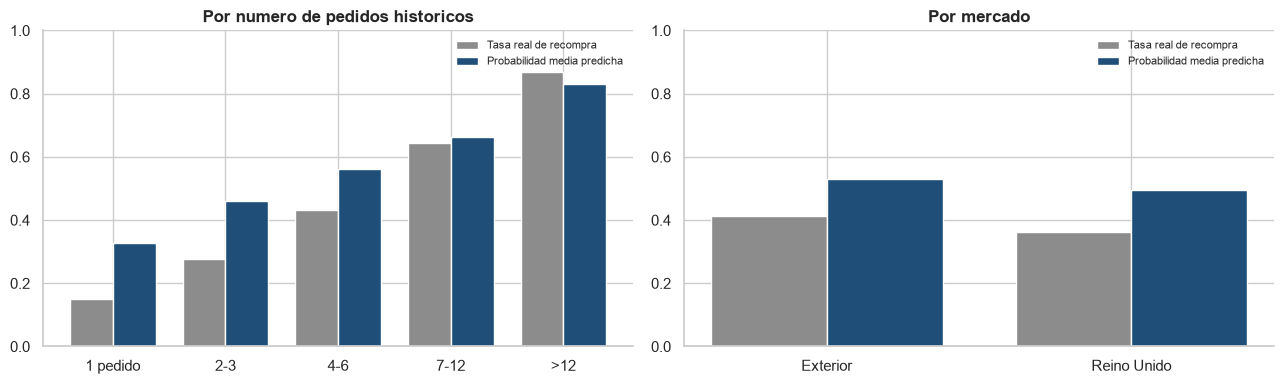

clientes-corte  tasa_real  prob_media  recall  \
Pedidos historicos 1 pedido          7,790.000      0.149       0.327   0.052   
                   2-3               7,065.000      0.278       0.462   0.452   
                   4-6               4,719.000      0.433       0.562   0.772   
                   7-12              3,335.000      0.645       0.661   0.920   
                   >12               2,153.000      0.868       0.831   0.990   
Mercado            Exterior          2,097.000      0.412       0.532   0.716   
                   Reino Unido      22,965.000      0.362       0.494   0.689   

                                precision  roc_auc  
Pedidos historicos 1 pedido         0.426    0.669  
                   2-3              0.423    0.655  
                   4-6              0.521    0.678  
                   7-12             0.695    0.692  
                   >12              0.899    0.840  
Mercado            Exterior         0.629    0.795  
                   Reino Unido      0.624    0.800

In [21]:
t = test.assign(p=p_te, pred=pred)
t['segmento_frecuencia'] = pd.cut(t['frecuencia'], [0, 1, 3, 6, 12, 1000], labels=['1 pedido', '2-3', '4-6', '7-12', '>12'])
t['mercado'] = t['exterior'].map({0: 'Reino Unido', 1: 'Exterior'})


def resumen_grupo(g):
    return pd.Series({'clientes-corte': len(g), 'tasa_real': g['y'].mean(), 'prob_media': g['p'].mean(),
                      'recall': recall_score(g['y'], g['pred']), 'precision': precision_score(g['y'], g['pred'], zero_division=0),
                      'roc_auc': roc_auc_score(g['y'], g['p']) if g['y'].nunique() > 1 else np.nan})


eq_frec = t.groupby('segmento_frecuencia', observed=True).apply(resumen_grupo)
eq_merc = t.groupby('mercado').apply(resumen_grupo)
equidad = pd.concat({'Pedidos historicos': eq_frec, 'Mercado': eq_merc})
equidad.to_csv(SALIDA / 'equidad_segmentos.csv')

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, tabla, titulo in [(axs[0], eq_frec, 'Por numero de pedidos historicos'), (axs[1], eq_merc, 'Por mercado')]:
    x = np.arange(len(tabla)); w = .38
    ax.bar(x - w / 2, tabla['tasa_real'], w, color=GRIS, label='Tasa real de recompra')
    ax.bar(x + w / 2, tabla['prob_media'], w, color=AZUL, label='Probabilidad media predicha')
    ax.set_xticks(x); ax.set_xticklabels(tabla.index.astype(str)); ax.set_title(titulo); ax.set_ylim(0, 1); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / '06_12_equidad_grupos.png', dpi=150, bbox_inches='tight'); plt.show()
R['rec_uk'] = coma(eq_merc.loc['Reino Unido', 'recall'], 2); R['rec_ext'] = coma(eq_merc.loc['Exterior', 'recall'], 2)
R['auc_uk'] = coma(eq_merc.loc['Reino Unido', 'roc_auc'], 3); R['auc_ext'] = coma(eq_merc.loc['Exterior', 'roc_auc'], 3)
R['rec_1'] = coma(eq_frec.loc['1 pedido', 'recall'] * 100, 0) + ' %'; R['pred_1'] = coma(eq_frec.loc['1 pedido', 'prob_media'] * 100, 0) + ' %'; R['real_1'] = coma(eq_frec.loc['1 pedido', 'tasa_real'] * 100, 0) + ' %'
R['auc_1'] = coma(eq_frec.loc['1 pedido', 'roc_auc'], 3); R['auc_gt12'] = coma(eq_frec.loc['>12', 'roc_auc'], 3)
equidad.round(3)

**Lectura.**
- **Mercado:** el modelo funciona de forma parecida en Reino Unido y en Exterior (ROC-AUC @@auc_uk@@ y @@auc_ext@@; recall @@rec_uk@@ y @@rec_ext@@). No hay evidencia de que el mercado de exportación sea tratado peor.
- **Antigüedad del vínculo:** en los clientes de **un solo pedido** el ROC-AUC es @@auc_1@@ (frente a @@auc_gt12@@ en los de más de 12 pedidos), y además el modelo **sobreestima**: predice en promedio @@pred_1@@ de probabilidad cuando la recompra real es de @@real_1@@. Con el umbral elegido solo se detecta el @@rec_1@@ de las recompras de ese grupo. Hay menos señal cuando hay poca historia, así que **no hay que usar el puntaje de un cliente nuevo como si fuera el de uno consolidado**: para ellos conviene una regla aparte (por ejemplo, una campaña de segunda compra) y revisión humana.

## 11. Valor de negocio: ¿a quién conviene dirigir la campaña?

Un puntaje solo sirve si cambia una decisión. Se ordena a los clientes de la prueba por probabilidad y se mide cuánta de la recompra y del **ingreso futuro real** (`gasto_futuro`) queda dentro del 10 %, 20 %, 30 %... superior. Se compara con el azar (contactar al azar captura una proporción igual a la fracción contactada).

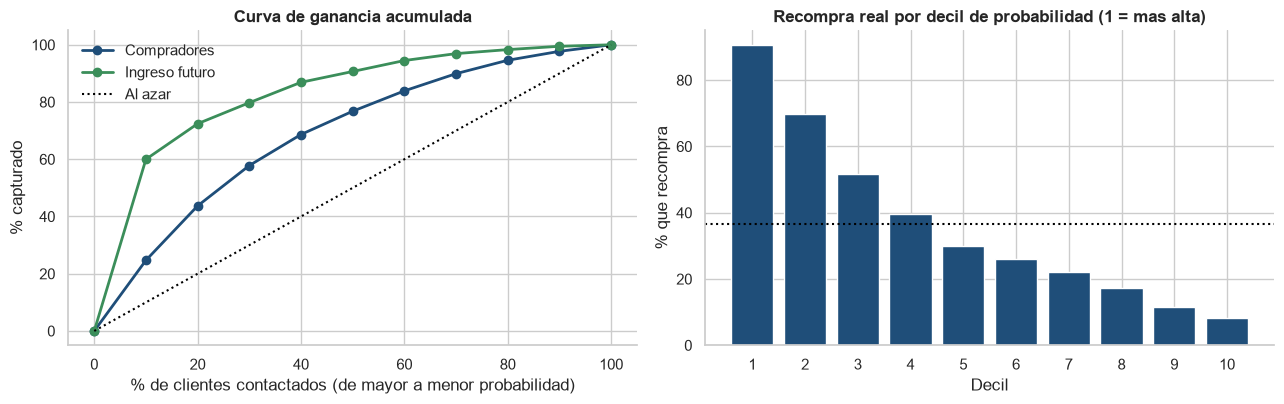

,clientes,prob_media,compradores,ingreso_futuro,tasa_real,captura_compradores_acum,captura_ingreso_acum,lift
decil,,,,,,,,
1,2507,0.876,2268,"6,072,927.280",0.905,0.247,0.600,2.468
2,2506,0.709,1747,"1,257,891.060",0.697,0.437,0.724,1.902
3,2506,0.603,1295,"743,847.890",0.517,0.578,0.798,1.410
4,2506,0.532,996,"720,979.590",0.397,0.686,0.869,1.084
5,2506,0.496,747,"382,208.200",0.298,0.768,0.907,0.813
6,2506,0.466,654,"387,784.720",0.261,0.839,0.945,0.712
7,2506,0.419,552,"244,985.840",0.220,0.899,0.969,0.601
8,2506,0.338,430,"141,470.760",0.172,0.946,0.983,0.468
9,2506,0.293,287,"117,763.460",0.115,0.977,0.995,0.312


In [22]:
o = test.assign(p=p_te).sort_values('p', ascending=False).reset_index(drop=True)
o['decil'] = pd.qcut(o.index, 10, labels=range(1, 11)).astype(int)
dec = o.groupby('decil').agg(clientes=('y', 'size'), prob_media=('p', 'mean'), compradores=('y', 'sum'), ingreso_futuro=('gasto_futuro', 'sum'))
dec['tasa_real'] = dec['compradores'] / dec['clientes']
dec['captura_compradores_acum'] = dec['compradores'].cumsum() / dec['compradores'].sum()
dec['captura_ingreso_acum'] = dec['ingreso_futuro'].cumsum() / dec['ingreso_futuro'].sum()
dec['lift'] = dec['tasa_real'] / o['y'].mean()
dec.to_csv(SALIDA / 'ganancia_deciles.csv')

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(0, 11) * 10
axs[0].plot(x, np.r_[0, dec['captura_compradores_acum'] * 100], marker='o', color=AZUL, lw=2, label='Compradores')
axs[0].plot(x, np.r_[0, dec['captura_ingreso_acum'] * 100], marker='o', color=VERDE, lw=2, label='Ingreso futuro')
axs[0].plot([0, 100], [0, 100], ':', color='black', label='Al azar')
axs[0].set_title('Curva de ganancia acumulada'); axs[0].set_xlabel('% de clientes contactados (de mayor a menor probabilidad)'); axs[0].set_ylabel('% capturado'); axs[0].legend(frameon=False)
axs[1].bar(dec.index, dec['tasa_real'] * 100, color=AZUL)
axs[1].axhline(o['y'].mean() * 100, ls=':', color='black'); axs[1].set_title('Recompra real por decil de probabilidad (1 = mas alta)')
axs[1].set_xlabel('Decil'); axs[1].set_ylabel('% que recompra'); axs[1].set_xticks(range(1, 11))
plt.tight_layout(); plt.savefig(FIG / '06_13_ganancia_deciles.png', dpi=150, bbox_inches='tight'); plt.show()
R['cap30_comp'] = coma(dec.loc[3, 'captura_compradores_acum'] * 100, 0)
R['cap30_ing'] = coma(dec.loc[3, 'captura_ingreso_acum'] * 100, 0)
R['cap10_ing'] = coma(dec.loc[1, 'captura_ingreso_acum'] * 100, 0)
R['lift1'] = coma(dec.loc[1, 'lift'], 1)
R['tasa_d1'] = coma(dec.loc[1, 'tasa_real'] * 100, 0); R['tasa_d10'] = coma(dec.loc[10, 'tasa_real'] * 100, 0)
dec.round(3)

**Lectura.** Los clientes del **decil superior** recompran @@tasa_d1@@ % de las veces (@@lift1@@ veces la tasa base) y los del decil inferior solo @@tasa_d10@@ %: el modelo **ordena bien**. El 30 % de clientes con mayor puntaje concentra el @@cap30_comp@@ % de los compradores y el @@cap30_ing@@ % del ingreso futuro.

**Cómo se traduce en decisiones.** Contactar a quienes ya iban a comprar tiene poco valor incremental. La utilidad real está en cruzar la **probabilidad** con el **valor del cliente**: los clientes de **alto valor y baja probabilidad** son los que más conviene retener (campaña personalizada), y los de **alta probabilidad** requieren poco esfuerzo. Esa matriz se construye en la sección siguiente y alimenta el dashboard.

## 12. Puesta en producción: puntaje de la cartera actual y exportación al dashboard

Para usar el modelo hoy se hace lo habitual: (1) **reentrenar con todos los datos etiquetados** (entrenamiento + prueba), (2) calcular las variables en la **fecha de corte actual** (10 de diciembre de 2011, un día después del último dato) y (3) puntuar a cada cliente. El resultado se exporta como tabla para Power BI.

Cada cliente se clasifica en una **matriz de acción** que cruza probabilidad y valor:

| | Valor histórico alto (≥ percentil 75) | Valor histórico bajo |
|---|---|---|
| **Probabilidad ≥ umbral** | **Fieles seguros**: mantener, sin gastar en descuentos | **Estables**: comunicación de bajo costo |
| **Probabilidad < umbral** | **Valiosos en riesgo**: prioridad de retención personalizada | **Reactivar**: campaña masiva de bajo costo |

5,852 clientes puntuados al 2011-12-10


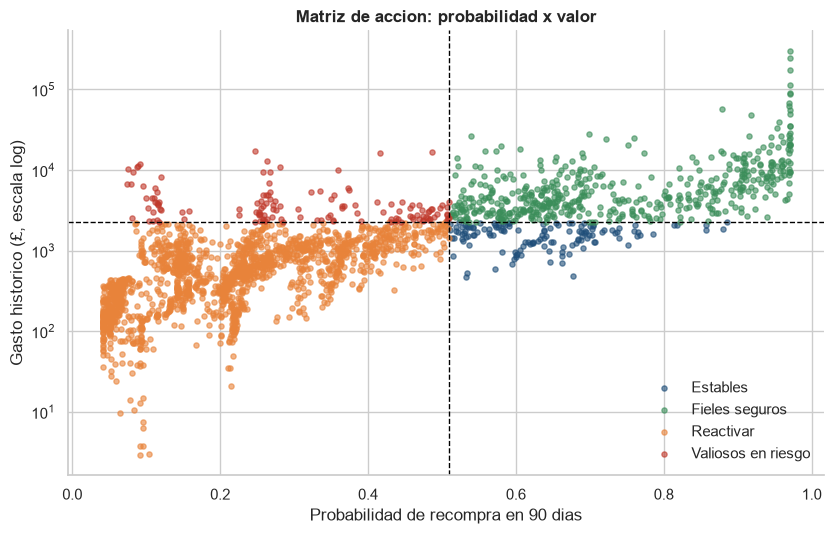

,clientes,prob_media,monetario_total,valor_en_riesgo,% de clientes,% del gasto historico
segmento_accion,,,,,,
Fieles seguros,1160,0.747,"12,153,151.220","284,549.234",0.198,0.722
Estables,313,0.620,"500,024.920","59,765.103",0.053,0.030
Valiosos en riesgo,303,0.306,"1,518,919.390","195,442.930",0.052,0.090
Reactivar,4076,0.204,"2,650,819.240","539,334.808",0.697,0.158


In [23]:
CORTE_ACTUAL = pd.Timestamp('2011-12-10')
panel_total = panel                                              # todos los cortes con objetivo observado (hasta 2011-09)
produccion = hacer(ganador, **mejores[ganador]).fit(panel_total[FEATS], panel_total['y'])

hoy = variables_al_corte(CORTE_ACTUAL, con_objetivo=False).merge(dim_cliente, on='cliente_key', how='left')
hoy['exterior'] = (hoy['pais_grupo_cliente'] == 'Exterior').astype(int)
hoy['prob_recompra_90d'] = produccion.predict_proba(hoy[FEATS])[:, 1]
hoy['decil'] = pd.qcut(hoy['prob_recompra_90d'].rank(method='first', ascending=False), 10, labels=range(1, 11)).astype(int)
p75 = hoy['monetario'].quantile(.75)
hoy['valor_alto'] = hoy['monetario'] >= p75
hoy['probable'] = hoy['prob_recompra_90d'] >= UMBRAL
hoy['segmento_accion'] = np.select(
    [hoy['probable'] & hoy['valor_alto'], hoy['probable'] & ~hoy['valor_alto'], ~hoy['probable'] & hoy['valor_alto']],
    ['Fieles seguros', 'Estables', 'Valiosos en riesgo'], default='Reactivar')
# Valor en riesgo (indicativo): gasto tipico por 90 dias del cliente x probabilidad de NO recomprar
hoy['gasto_tipico_90d'] = hoy['monetario'] / np.maximum(hoy['antiguedad'], 90) * 90
hoy['valor_en_riesgo'] = (1 - hoy['prob_recompra_90d']) * hoy['gasto_tipico_90d']

scoring = hoy[['cliente_key', 'pais_grupo_cliente', 'recencia', 'frecuencia', 'monetario', 'antiguedad', 'prob_recompra_90d',
               'decil', 'segmento_accion', 'gasto_tipico_90d', 'valor_en_riesgo']].sort_values('valor_en_riesgo', ascending=False)
scoring.to_csv(SALIDA / 'scoring_clientes.csv', index=False)
print(f'{len(scoring):,} clientes puntuados al {CORTE_ACTUAL:%Y-%m-%d}')

acc = scoring.groupby('segmento_accion').agg(clientes=('cliente_key', 'size'), prob_media=('prob_recompra_90d', 'mean'),
                                              monetario_total=('monetario', 'sum'), valor_en_riesgo=('valor_en_riesgo', 'sum'))
acc['% de clientes'] = acc['clientes'] / acc['clientes'].sum()
acc['% del gasto historico'] = acc['monetario_total'] / acc['monetario_total'].sum()
acc = acc.reindex(['Fieles seguros', 'Estables', 'Valiosos en riesgo', 'Reactivar'])
acc.to_csv(SALIDA / 'matriz_accion.csv')

fig, ax = plt.subplots(figsize=(8.5, 5.5))
colores = {'Fieles seguros': VERDE, 'Estables': AZUL, 'Valiosos en riesgo': ROJO, 'Reactivar': NARANJA}
for s, g in scoring.sample(2500, random_state=SEMILLA).groupby('segmento_accion'):
    ax.scatter(g['prob_recompra_90d'], g['monetario'], s=14, alpha=.6, color=colores[s], label=s)
ax.set_yscale('log'); ax.axvline(UMBRAL, color='black', ls='--', lw=1); ax.axhline(p75, color='black', ls='--', lw=1)
ax.set_xlabel('Probabilidad de recompra en 90 dias'); ax.set_ylabel('Gasto historico (£, escala log)')
ax.set_title('Matriz de accion: probabilidad x valor'); ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig(FIG / '06_14_matriz_accion.png', dpi=150, bbox_inches='tight'); plt.show()
R['n_scoring'] = f'{len(scoring):,}'.replace(',', '.')
for k, s in {'fieles': 'Fieles seguros', 'estables': 'Estables', 'riesgo': 'Valiosos en riesgo', 'reactivar': 'Reactivar'}.items():
    R[f'n_{k}'] = f'{int(acc.loc[s, "clientes"]):,}'.replace(',', '.')
    R[f'pg_{k}'] = coma(acc.loc[s, '% del gasto historico'] * 100, 0)
R['p75'] = f'{p75:,.0f}'.replace(',', '.')
R['var_total'] = f'{scoring["valor_en_riesgo"].sum():,.0f}'.replace(',', '.')
acc.round(3)

**Lectura.** De los @@n_scoring@@ clientes puntuados, @@n_riesgo@@ son **valiosos en riesgo** (gasto histórico ≥ £@@p75@@ y probabilidad baja): representan @@pg_riesgo@@ % del gasto histórico total y son el **grupo prioritario para una acción de retención personalizada** (contacto comercial, oferta a medida). Los @@n_fieles@@ **fieles seguros** concentran @@pg_fieles@@ % del gasto y no requieren descuentos; los @@n_reactivar@@ clientes a **reactivar** y los @@n_estables@@ **estables** se atienden con comunicación masiva de bajo costo.

La columna `valor_en_riesgo` es un **indicador de priorización** (probabilidad de no comprar × gasto típico por 90 días), no una previsión contable.

In [24]:
# Cierre tecnico: guarda las cifras clave en un archivo para que el documento, las diapositivas y el dashboard usen los mismos numeros
cifras = {'modelo': ganador, 'umbral': UMBRAL, 'horizonte_dias': HORIZONTE, 'filas_entrenamiento': len(train), 'filas_prueba': len(test),
          'cv_pr_auc': {n: float(cv_ajustado[n]['pr_auc'].mean()) for n in cv_ajustado}, 'cv_pr_auc_base': float(cv_pred['Regla de recencia (base)']['pr_auc'].mean()),
          'test': {k: float(v) for k, v in res[ganador].items()}, 'test_base': {k: float(v) for k, v in res['Regla de recencia (base)'].items()},
          'tasa_base_test': float(yte.mean()), 'tasa_base_train': float(ytr.mean()),
          'matriz': {'VP': int(tp), 'FP': int(fp), 'FN': int(fn), 'VN': int(tn)},
          'ic95_pr_auc': [float(ic_pr[0]), float(ic_pr[1])], 'ic95_roc_auc': [float(ic_roc[0]), float(ic_roc[1])],
          'hiperparametros': {k: {a: (float(b) if isinstance(b, (np.floating, float)) else (int(b) if isinstance(b, (np.integer, int)) else b)) for a, b in v.items()} for k, v in mejores.items()},
          'matriz_accion': {s: int(acc.loc[s, 'clientes']) for s in acc.index}}
(SALIDA / 'resultados_modelo.json').write_text(json.dumps(cifras, indent=2, ensure_ascii=False), encoding='utf-8')
(SALIDA / 'textos_modelo.json').write_text(json.dumps(R, indent=2, ensure_ascii=False), encoding='utf-8')
print('Archivos en', SALIDA)
for p in sorted(SALIDA.iterdir()): print(' -', p.name)

Archivos en C:\Users\User\Downloads\Analisis de datos entrega2\I4_final\data\processed\modelo_predictivo
 - ablacion.csv
 - comparacion_cv.csv
 - equidad_segmentos.csv
 - estabilidad_por_corte.csv
 - ganancia_deciles.csv
 - importancia_permutacion.csv
 - matriz_accion.csv
 - metricas_test.csv
 - resultados_modelo.json
 - scoring_clientes.csv
 - textos_modelo.json


## 13. Ética, riesgos y limitaciones

**Aspectos éticos y normativos**
- **Datos personales.** El `Customer ID` es un identificador numérico anónimo y el conjunto no trae nombre, contacto ni datos demográficos. Aun así, un historial de compras vinculado a una persona o empresa identificable es dato personal bajo normas como el RGPD/UK GDPR (el comercio es del Reino Unido). En un uso real haría falta base legal para el perfilamiento, minimización de datos y posibilidad de oposición.
- **Uso responsable.** El modelo **prioriza esfuerzos comerciales**; no debe usarse para **negar servicio, precio o crédito**. Un puntaje bajo no significa "mal cliente", significa "menos probable de comprar pronto".
- **Equidad.** Se verificó que el desempeño es parecido entre Reino Unido y Exterior. Con clientes de pocos pedidos el modelo es menos confiable; esas decisiones deben tomarse con cautela y supervisión humana.
- **Transparencia.** Las variables son simples (RFM y actividad reciente) y se pueden explicar a un directivo; se documentó qué variables pesan y por qué.

**Limitaciones**
1. **Solo dos años de historia:** el modelo vio un único ciclo estacional completo en entrenamiento; la estacionalidad está subestimada.
2. **Deriva:** la tasa de recompra cambia con la temporada y la economía. El modelo debe **reentrenarse y recalibrarse** periódicamente (por ejemplo, cada trimestre).
3. **Clientes no identificados** (22 % de las líneas) quedan fuera: no se pueden predecir ni contactar.
4. **No hay datos de costos** (margen, costo de contacto): la matriz de acción es una guía, no un cálculo de rentabilidad.
5. **Asociación, no causalidad:** que un cliente sea probable no significa que la campaña lo haga comprar; para medir el efecto de una campaña haría falta un experimento con grupo de control.
6. **Un solo comercio:** los resultados no se generalizan a otros negocios.

## 14. Conclusiones del modelo

1. **Es posible anticipar la recompra con un desempeño útil:** @@ganador@@ logra PR-AUC @@pr_test@@ y ROC-AUC @@roc_test@@ en un periodo posterior que no vio, @@mejora_pr@@ % por encima de la regla de recencia.
2. **Lo que predice es hábito y actividad reciente**, no rasgos del cliente: recencia, frecuencia y ritmo de compra. Es coherente con el análisis exploratorio y con la lógica del negocio.
3. **El modelo ordena bien:** el 30 % de clientes con mayor probabilidad concentra el @@cap30_comp@@ % de las recompras y el @@cap30_ing@@ % del ingreso futuro.
4. **La acción de mayor valor** está en cruzar probabilidad y valor: los @@n_riesgo@@ clientes **valiosos en riesgo** merecen retención personalizada; no hace falta gastar descuentos en los **fieles seguros**.
5. **Hay que usarlo con prudencia:** monitorear la deriva, reentrenar con regularidad, ser cauteloso con clientes nuevos y medir con un experimento el efecto real de las campañas.